In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, KFold, cross_validate, cross_val_predict
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder, FunctionTransformer
from sklearn.linear_model import LinearRegression, Ridge, Lasso, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, ConfusionMatrixDisplay)

RANDOM_STATE = 42
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", None)

In [2]:
df = pd.read_csv("data/stress_dataset_clean.csv")

stress_order = ["Low", "Medium", "High", "Very High"]
df["stress"] = df["Stress_Level"].map({s: i for i, s in enumerate(stress_order, start=1)})
assert df["stress"].notna().all()
df["high_stress"] = (df["stress"] >= 3).astype(int)

X = df.drop(columns=["Stress_Level", "Mental_Health_Score", "Usage_Band", "stress", "high_stress"])
y_reg = df["stress"]
y_clf = df["high_stress"]

print("Shape:", df.shape)
print(df["Stress_Level"].value_counts().reindex(stress_order))
print("High-stress share:", round(y_clf.mean(), 3))

Shape: (4998, 16)
Stress_Level
Low           643
Medium       1295
High         1439
Very High    1621
Name: count, dtype: int64
High-stress share: 0.612


In [3]:
X_train, X_test, y_train_reg, y_test_reg = train_test_split(
    X, y_reg, test_size=0.2, random_state=RANDOM_STATE, stratify=y_reg
)
y_train_clf, y_test_clf = y_clf.loc[X_train.index], y_clf.loc[X_test.index]
print("Training rows:", len(X_train), " Test rows:", len(X_test))

Training rows: 3998  Test rows: 1000


In [4]:
numeric = ["Age", "Avg_Daily_Usage_Hours", "Daily_Unlocks", "Study_Hours",
           "Physical_Activity_Hours", "Sleep_Hours_Per_Night"]
engineered = ["social_to_study_ratio", "unlocks_per_usage_hour", "sleep_deficit"]
level_order = ["High School", "Undergraduate", "Graduate"]
nominal = ["Gender", "Country", "Most_Used_Platform", "Purpose_Of_Use"]


def add_features(data):
    result = data.copy()
    result["social_to_study_ratio"] = result["Avg_Daily_Usage_Hours"] / result["Study_Hours"].clip(lower=0.1)
    result["unlocks_per_usage_hour"] = result["Daily_Unlocks"] / result["Avg_Daily_Usage_Hours"].clip(lower=0.1)
    result["sleep_deficit"] = (7 - result["Sleep_Hours_Per_Night"]).clip(lower=0)
    return result


def preprocessor():
    columns = ColumnTransformer([
        ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), numeric + engineered),
        ("level", make_pipeline(OrdinalEncoder(categories=[level_order]), StandardScaler()), ["Academic_Level"]),
        ("nom", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20, sparse_output=False), nominal),
    ], verbose_feature_names_out=False)
    return Pipeline([("features", FunctionTransformer(add_features)), ("columns", columns)])


def full_pipeline(model):
    return Pipeline([("prep", preprocessor()), ("model", model)])


def feature_names(fitted_pipeline):
    return fitted_pipeline.named_steps["prep"].named_steps["columns"].get_feature_names_out()

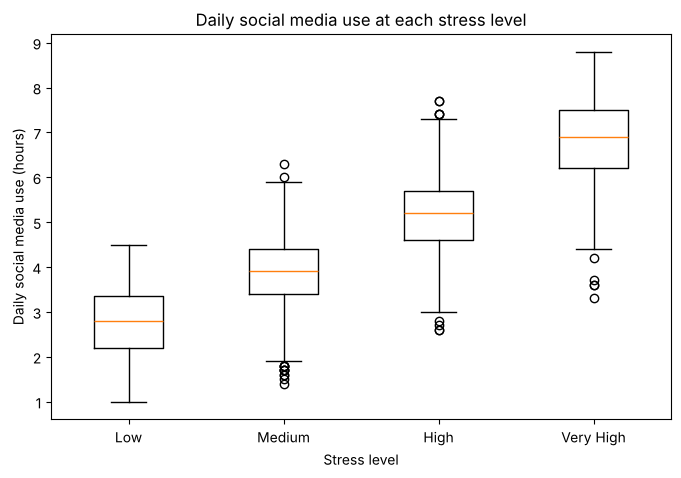

Stress_Level
Low          2.77
Medium       3.86
High         5.19
Very High    6.87
Name: Avg_Daily_Usage_Hours, dtype: float64
Sleep_Hours_Per_Night     -0.82
Study_Hours               -0.80
Physical_Activity_Hours   -0.56
Age                       -0.08
Daily_Unlocks              0.86
Avg_Daily_Usage_Hours      0.89
Name: stress, dtype: float64


In [5]:
fig, ax = plt.subplots(figsize=(8, 5))
groups = [df.loc[df["stress"] == i, "Avg_Daily_Usage_Hours"] for i in range(1, 5)]
ax.boxplot(groups, tick_labels=stress_order)
ax.set_xlabel("Stress level")
ax.set_ylabel("Daily social media use (hours)")
ax.set_title("Daily social media use at each stress level")
plt.show()

print(df.groupby("Stress_Level")["Avg_Daily_Usage_Hours"].mean().reindex(stress_order).round(2))
print(df[numeric + ["stress"]].corr(method="spearman")["stress"].drop("stress").round(2).sort_values())

In [6]:
reg_cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
reg_scoring = {"MAE": "neg_mean_absolute_error", "MSE": "neg_mean_squared_error", "R²": "r2"}


def cv_regression(model, X_data):
    s = cross_validate(model, X_data, y_train_reg, cv=reg_cv, scoring=reg_scoring, return_train_score=True)
    return {
        "Train R²": s["train_R²"].mean(),
        "CV MAE": -s["test_MAE"].mean(),
        "CV RMSE": np.sqrt(-s["test_MSE"].mean()),
        "CV R²": s["test_R²"].mean(),
    }

stress = 0.05 + 0.54 × usage_hours
Predicted change for +1 hour a day:  0.54 stress levels
Predicted change for +2 hours a day: 1.08 stress levels


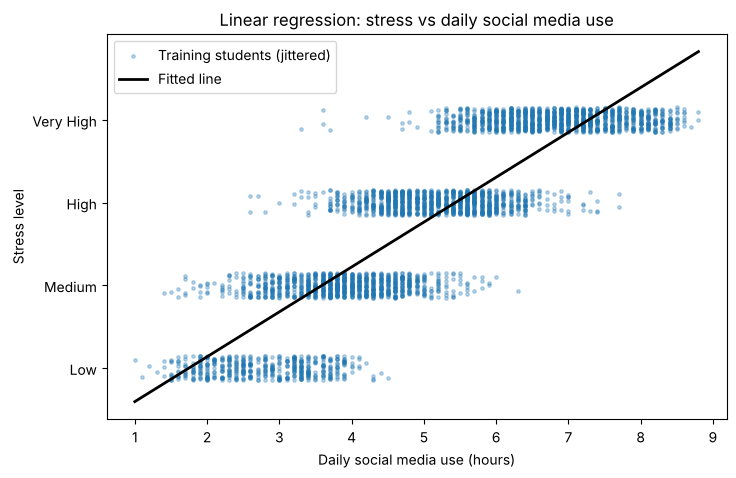

In [7]:
model_1 = LinearRegression().fit(X_train[["Avg_Daily_Usage_Hours"]], y_train_reg)
b0, b1 = model_1.intercept_, model_1.coef_[0]
print(f"stress = {b0:.2f} + {b1:.2f} × usage_hours")
print(f"Predicted change for +1 hour a day:  {b1:.2f} stress levels")
print(f"Predicted change for +2 hours a day: {2 * b1:.2f} stress levels")

x_line = pd.DataFrame({"Avg_Daily_Usage_Hours": np.linspace(X_train["Avg_Daily_Usage_Hours"].min(),
                                                          X_train["Avg_Daily_Usage_Hours"].max(), 200)})
rng = np.random.default_rng(0)
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(X_train["Avg_Daily_Usage_Hours"], y_train_reg + rng.uniform(-0.15, 0.15, len(y_train_reg)),
           s=6, alpha=0.3, label="Training students (jittered)")
ax.plot(x_line["Avg_Daily_Usage_Hours"], model_1.predict(x_line), color="black", lw=2, label="Fitted line")
ax.set_yticks([1, 2, 3, 4], stress_order)
ax.set_xlabel("Daily social media use (hours)")
ax.set_ylabel("Stress level")
ax.set_title("Linear regression: stress vs daily social media use")
ax.legend()
plt.show()

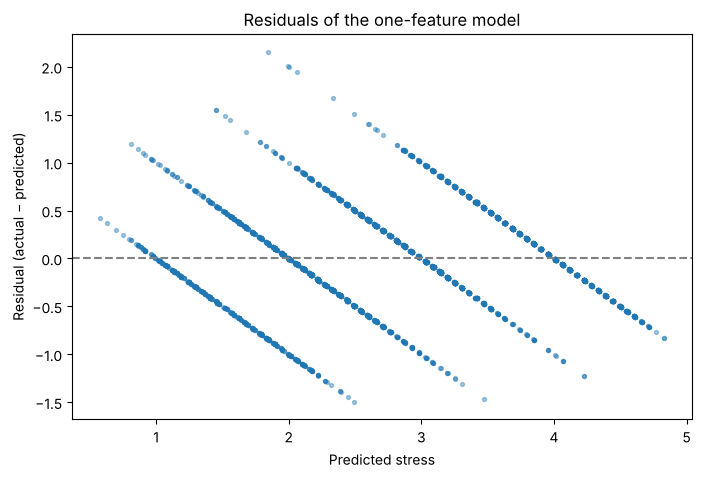

In [8]:
cv_pred_1 = cross_val_predict(LinearRegression(), X_train[["Avg_Daily_Usage_Hours"]], y_train_reg, cv=reg_cv)
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(cv_pred_1, y_train_reg - cv_pred_1, s=8, alpha=0.4)
ax.axhline(0, linestyle="--", color="grey")
ax.set_xlabel("Predicted stress")
ax.set_ylabel("Residual (actual − predicted)")
ax.set_title("Residuals of the one-feature model")
plt.show()

In [9]:
noise_rng = np.random.default_rng(0)
X_train_noisy = X_train.copy()
for k in range(10):
    X_train_noisy[f"noise_{k}"] = noise_rng.normal(size=len(X_train_noisy))


def noisy_pipeline(model):
    noise_cols = [f"noise_{k}" for k in range(10)]
    prep = preprocessor()
    prep.named_steps["columns"].transformers.append(("noise", StandardScaler(), noise_cols))
    return Pipeline([("prep", prep), ("model", model)])


reg_results = pd.DataFrame({
    "Usage only": cv_regression(LinearRegression(), X_train[["Avg_Daily_Usage_Hours"]]),
    "All features": cv_regression(full_pipeline(LinearRegression()), X_train),
    "All features + 10 noise": cv_regression(noisy_pipeline(LinearRegression()), X_train_noisy),
}).T
print(reg_results.round(3))

model_2 = full_pipeline(LinearRegression()).fit(X_train, y_train_reg)
coefs_2 = pd.Series(model_2[-1].coef_, index=feature_names(model_2))
print("Largest coefficients (stress levels per +1 standard deviation / per category):")
print(coefs_2.reindex(coefs_2.abs().sort_values(ascending=False).index).head(12).round(3))

                         Train R²  CV MAE  CV RMSE  CV R²
Usage only                  0.760   0.406    0.505  0.760
All features                0.808   0.368    0.459  0.801
All features + 10 noise     0.808   0.369    0.460  0.801
Largest coefficients (stress levels per +1 standard deviation / per category):
Avg_Daily_Usage_Hours    0.592
Sleep_Hours_Per_Night   -0.374
Country_Mexico           0.222
Country_China            0.220
Country_Bangladesh      -0.214
Country_Poland           0.207
Country_Sri Lanka       -0.202
Country_Spain            0.179
Country_New Zealand     -0.174
Country_Russia           0.165
Country_France          -0.157
Country_Canada          -0.123
dtype: float64


Ridge:
         Train R²  CV MAE  CV RMSE   CV R²
0.1       0.8076  0.3683   0.4589  0.8014
1.0       0.8076  0.3682   0.4588  0.8015
10.0      0.8072  0.3678   0.4585  0.8017
50.0      0.8050  0.3687   0.4597  0.8008
100.0     0.8029  0.3700   0.4613  0.7994
500.0     0.7940  0.3774   0.4698  0.7919
1000.0    0.7872  0.3832   0.4769  0.7856
Lasso:
        Train R²  CV MAE  CV RMSE   CV R²
0.001    0.8060  0.3681   0.4588  0.8015
0.005    0.7994  0.3726   0.4632  0.7977
0.010    0.7967  0.3747   0.4656  0.7956
0.020    0.7952  0.3761   0.4671  0.7943
0.050    0.7924  0.3791   0.4700  0.7917
0.100    0.7842  0.3863   0.4792  0.7835
Best Ridge alpha: 10.0  Best Lasso alpha: 0.001
Features kept by Lasso: 36 of 54
                         Linear regression  Ridge (alpha=10.0)  Lasso (alpha=0.001)
Age                                 -0.031              -0.026               -0.016
Avg_Daily_Usage_Hours                0.592               0.516                0.559
Daily_Unlocks               

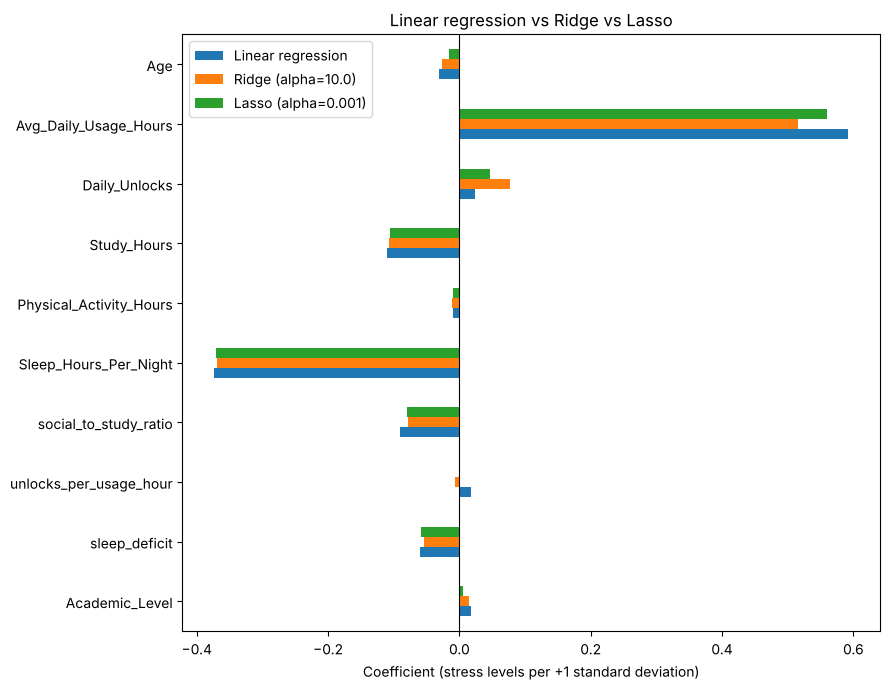

In [10]:
ridge_alphas = [0.1, 1, 10, 50, 100, 500, 1000]
lasso_alphas = [0.001, 0.005, 0.01, 0.02, 0.05, 0.1]

ridge_cv = pd.DataFrame({a: cv_regression(full_pipeline(Ridge(alpha=a)), X_train) for a in ridge_alphas}).T
lasso_cv = pd.DataFrame({a: cv_regression(full_pipeline(Lasso(alpha=a, max_iter=10000)), X_train)
                         for a in lasso_alphas}).T
print("Ridge:\n", ridge_cv.round(4))
print("Lasso:\n", lasso_cv.round(4))

best_ridge_alpha = ridge_cv["CV R²"].idxmax()
best_lasso_alpha = lasso_cv["CV R²"].idxmax()
print("Best Ridge alpha:", best_ridge_alpha, " Best Lasso alpha:", best_lasso_alpha)

reg_models = {
    "Linear regression": full_pipeline(LinearRegression()),
    f"Ridge (alpha={best_ridge_alpha})": full_pipeline(Ridge(alpha=best_ridge_alpha)),
    f"Lasso (alpha={best_lasso_alpha})": full_pipeline(Lasso(alpha=best_lasso_alpha, max_iter=10000)),
}
coef_table = pd.DataFrame({name: m.fit(X_train, y_train_reg)[-1].coef_ for name, m in reg_models.items()},
                          index=feature_names(model_2))
print("Features kept by Lasso:", int((coef_table.iloc[:, 2].abs() > 1e-6).sum()), "of", len(coef_table))
print(coef_table.loc[numeric + engineered + ["Academic_Level"]].round(3))

ax = coef_table.loc[(numeric + engineered + ["Academic_Level"])[::-1]].plot(kind="barh", figsize=(9, 7))
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Coefficient (stress levels per +1 standard deviation)")
ax.set_title("Linear regression vs Ridge vs Lasso")
plt.tight_layout()
plt.show()

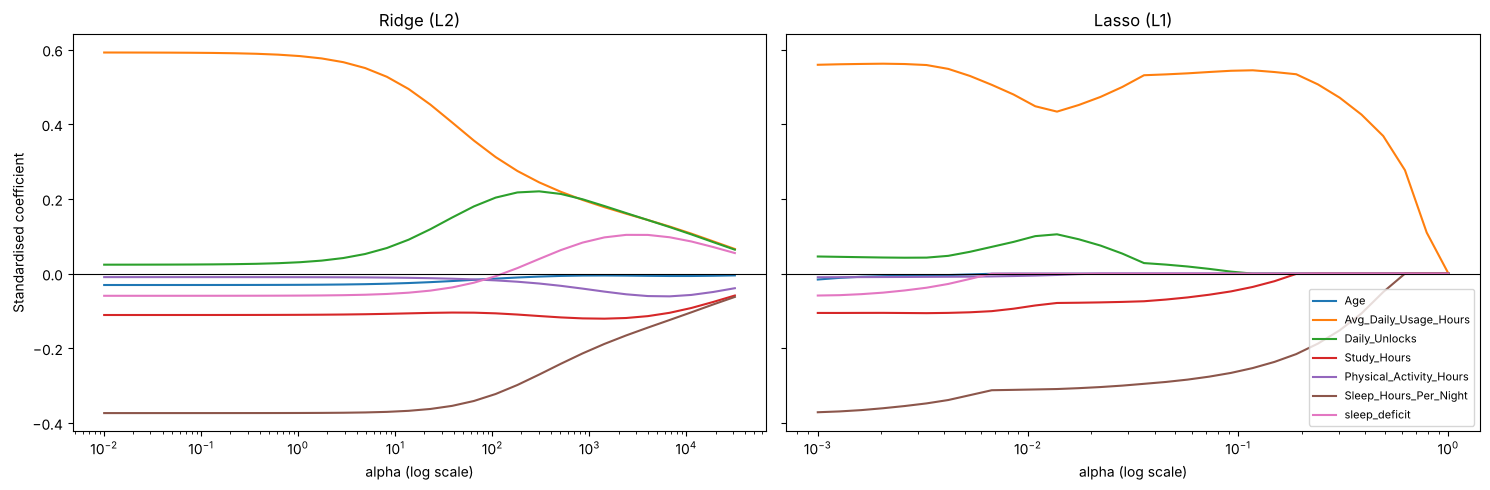

In [11]:
path_alphas_ridge = np.logspace(-2, 4.5, 30)
path_alphas_lasso = np.logspace(-3, 0, 30)
shown = numeric + ["sleep_deficit"]
idx = [list(feature_names(model_2)).index(f) for f in shown]

ridge_path = np.array([full_pipeline(Ridge(alpha=a)).fit(X_train, y_train_reg)[-1].coef_[idx]
                       for a in path_alphas_ridge])
lasso_path = np.array([full_pipeline(Lasso(alpha=a, max_iter=10000)).fit(X_train, y_train_reg)[-1].coef_[idx]
                       for a in path_alphas_lasso])

fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
for ax, alphas, path, title in [(axes[0], path_alphas_ridge, ridge_path, "Ridge (L2)"),
                                (axes[1], path_alphas_lasso, lasso_path, "Lasso (L1)")]:
    for j, name in enumerate(shown):
        ax.plot(alphas, path[:, j], label=name)
    ax.set_xscale("log")
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_xlabel("alpha (log scale)")
    ax.set_title(title)
axes[0].set_ylabel("Standardised coefficient")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

Baseline accuracy (always predict the majority class): 0.612


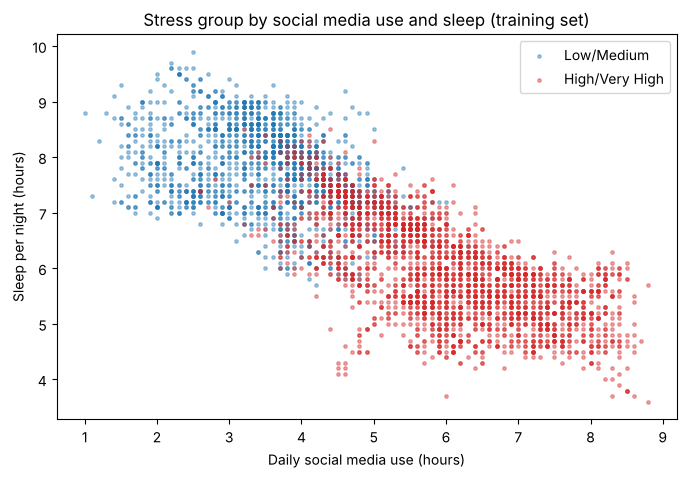

In [12]:
clf_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
clf_metrics = ["accuracy", "precision", "recall", "f1"]


def cv_classification(model, X_data, y_data=None):
    y_data = y_train_clf if y_data is None else y_data
    s = cross_validate(model, X_data, y_data, cv=clf_cv, scoring=clf_metrics, return_train_score=True)
    row = {"Train accuracy": s["train_accuracy"].mean()}
    row.update({f"CV {m}": s[f"test_{m}"].mean() for m in clf_metrics})
    row["CV F1 sd"] = s["test_f1"].std()
    return row


baseline = max(y_train_clf.mean(), 1 - y_train_clf.mean())
print("Baseline accuracy (always predict the majority class):", round(baseline, 3))

two_features = ["Avg_Daily_Usage_Hours", "Sleep_Hours_Per_Night"]
X_train_2f = X_train[two_features]

fig, ax = plt.subplots(figsize=(8, 5))
for label, name, colour in [(0, "Low/Medium", "tab:blue"), (1, "High/Very High", "tab:red")]:
    pts = X_train_2f[y_train_clf == label]
    ax.scatter(pts["Avg_Daily_Usage_Hours"], pts["Sleep_Hours_Per_Night"], s=6, alpha=0.4, color=colour, label=name)
ax.set_xlabel("Daily social media use (hours)")
ax.set_ylabel("Sleep per night (hours)")
ax.set_title("Stress group by social media use and sleep (training set)")
ax.legend()
plt.show()

Coefficients (log-odds per +1 standard deviation):
Avg_Daily_Usage_Hours    3.064
Sleep_Hours_Per_Night   -1.541
dtype: float64
Odds ratios:
Avg_Daily_Usage_Hours    21.404
Sleep_Hours_Per_Night     0.214
dtype: float64


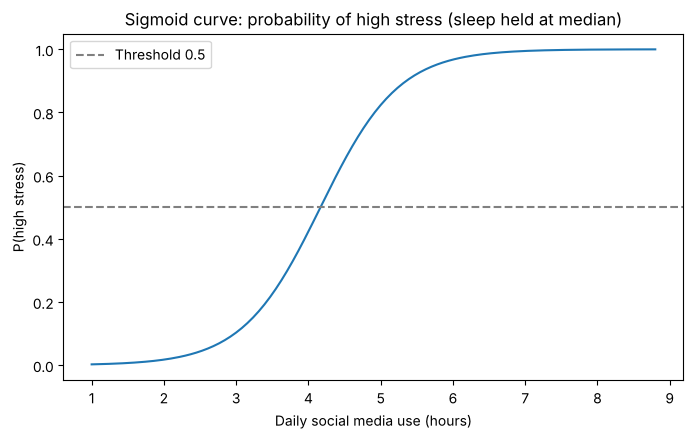

In [13]:
log_reg_2f = make_pipeline(StandardScaler(), LogisticRegression(random_state=RANDOM_STATE)).fit(X_train_2f, y_train_clf)
print("Coefficients (log-odds per +1 standard deviation):")
print(pd.Series(log_reg_2f[-1].coef_[0], index=two_features).round(3))
print("Odds ratios:")
print(pd.Series(np.exp(log_reg_2f[-1].coef_[0]), index=two_features).round(3))

usage_grid = pd.DataFrame({
    "Avg_Daily_Usage_Hours": np.linspace(X_train_2f["Avg_Daily_Usage_Hours"].min(),
                                         X_train_2f["Avg_Daily_Usage_Hours"].max(), 200),
    "Sleep_Hours_Per_Night": X_train_2f["Sleep_Hours_Per_Night"].median(),
})
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(usage_grid["Avg_Daily_Usage_Hours"], log_reg_2f.predict_proba(usage_grid)[:, 1])
ax.axhline(0.5, linestyle="--", color="grey", label="Threshold 0.5")
ax.set_xlabel("Daily social media use (hours)")
ax.set_ylabel("P(high stress)")
ax.set_title("Sigmoid curve: probability of high stress (sleep held at median)")
ax.legend()
plt.show()

In [14]:
k_results = pd.DataFrame({k: cv_classification(make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k)),
                                                X_train_2f)
                          for k in [1, 5, 10, 20, 50]}).T
k_results.index.name = "k"
print(k_results.round(3))
best_k = int(k_results["CV f1"].idxmax())
print("Best k by CV F1:", best_k)


def plot_boundary(model, X_plot, y_plot, title, ax):
    f1, f2 = X_plot.columns
    xx, yy = np.meshgrid(np.linspace(X_plot[f1].min() - 0.5, X_plot[f1].max() + 0.5, 300),
                         np.linspace(X_plot[f2].min() - 0.5, X_plot[f2].max() + 0.5, 300))
    zz = model.predict(pd.DataFrame({f1: xx.ravel(), f2: yy.ravel()})).reshape(xx.shape)
    ax.contourf(xx, yy, zz, alpha=0.25, levels=[-0.5, 0.5, 1.5], colors=["tab:blue", "tab:red"])
    for label, name, colour in [(0, "Low/Medium", "tab:blue"), (1, "High/Very High", "tab:red")]:
        pts = X_plot[y_plot == label]
        ax.scatter(pts[f1], pts[f2], s=6, alpha=0.4, color=colour, label=name)
    ax.set_xlabel("Daily social media use (hours)")
    ax.set_ylabel("Sleep per night (hours)")
    ax.set_title(title)

    Train accuracy  CV accuracy  CV precision  CV recall  CV f1  CV F1 sd
k                                                                        
1            0.913        0.865         0.888      0.893  0.890     0.007
5            0.914        0.891         0.908      0.915  0.912     0.008
10           0.909        0.898         0.925      0.908  0.916     0.008
20           0.904        0.902         0.922      0.918  0.920     0.009
50           0.905        0.903         0.917      0.925  0.921     0.009
Best k by CV F1: 50


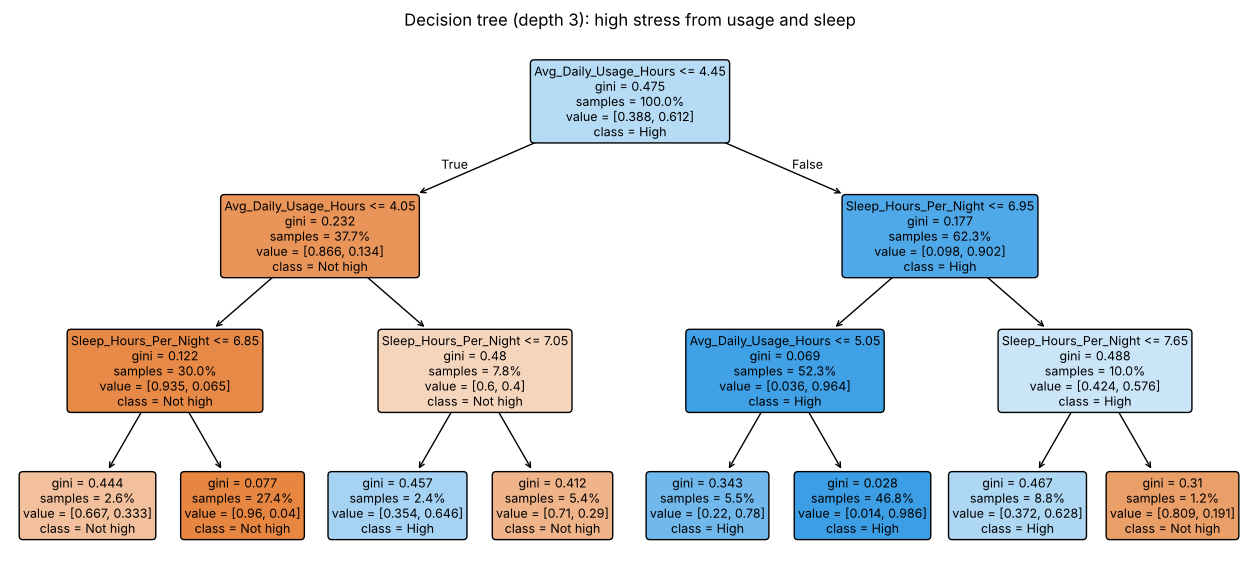

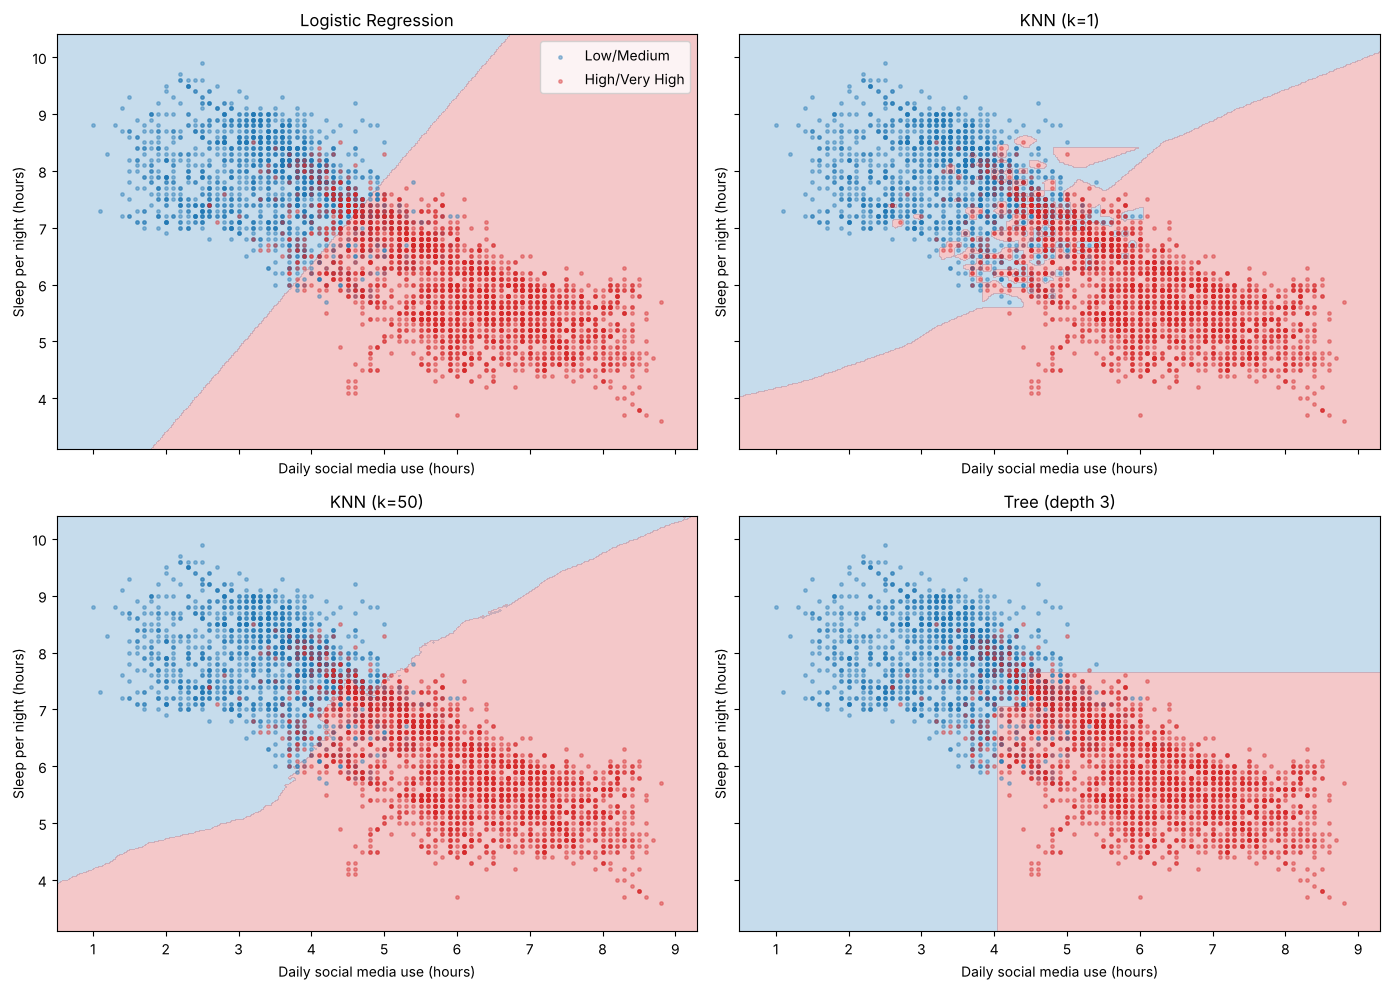

In [15]:
tree_2f = DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE).fit(X_train_2f, y_train_clf)

plt.figure(figsize=(16, 7))
plot_tree(tree_2f, feature_names=two_features, class_names=["Not high", "High"],
          filled=True, rounded=True, proportion=True, fontsize=9)
plt.title("Decision tree (depth 3): high stress from usage and sleep")
plt.show()

boundary_models = [
    ("Logistic Regression", log_reg_2f),
    ("KNN (k=1)", make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=1)).fit(X_train_2f, y_train_clf)),
    (f"KNN (k={best_k})", make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=best_k)).fit(X_train_2f, y_train_clf)),
    ("Tree (depth 3)", tree_2f),
]
fig, axes = plt.subplots(2, 2, figsize=(14, 10), sharex=True, sharey=True)
for ax, (name, m) in zip(axes.ravel(), boundary_models):
    plot_boundary(m, X_train_2f, y_train_clf, name, ax)
axes[0, 0].legend()
plt.tight_layout()
plt.show()

           Train accuracy  CV accuracy  CV f1
max_depth                                    
1                   0.889        0.886  0.909
2                   0.889        0.886  0.909
3                   0.903        0.897  0.916
4                   0.910        0.896  0.917
5                   0.919        0.896  0.916
6                   0.929        0.901  0.920
7                   0.939        0.903  0.922
8                   0.954        0.903  0.920
9                   0.967        0.905  0.922
10                  0.976        0.907  0.924
11                  0.984        0.905  0.922
12                  0.991        0.912  0.928
13                  0.995        0.913  0.929
14                  0.998        0.912  0.929
15                  0.999        0.910  0.927
Best depth by CV F1: 13


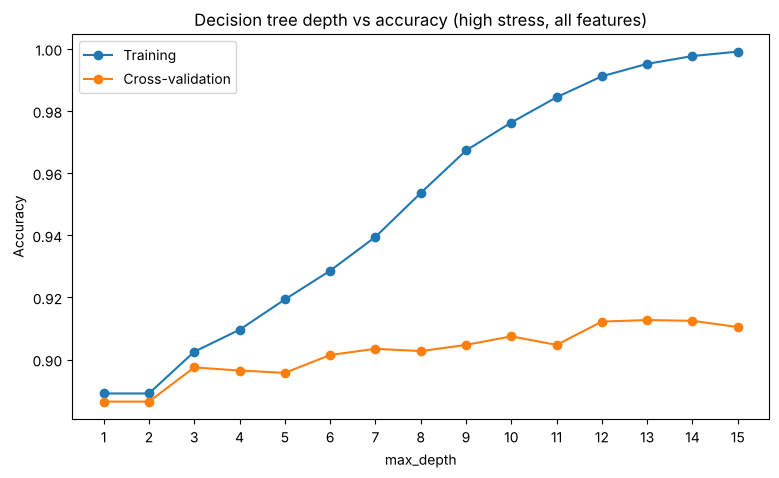

In [16]:
depth_rows = []
for depth in range(1, 16):
    s = cross_validate(full_pipeline(DecisionTreeClassifier(max_depth=depth, random_state=RANDOM_STATE)),
                       X_train, y_train_clf, cv=clf_cv, scoring=["accuracy", "f1"], return_train_score=True)
    depth_rows.append({"max_depth": depth, "Train accuracy": s["train_accuracy"].mean(),
                       "CV accuracy": s["test_accuracy"].mean(), "CV f1": s["test_f1"].mean()})
depth_results = pd.DataFrame(depth_rows).set_index("max_depth")
print(depth_results.round(3))
best_depth = int(depth_results["CV f1"].idxmax())
print("Best depth by CV F1:", best_depth)

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(depth_results.index, depth_results["Train accuracy"], marker="o", label="Training")
ax.plot(depth_results.index, depth_results["CV accuracy"], marker="o", label="Cross-validation")
ax.set_xlabel("max_depth")
ax.set_ylabel("Accuracy")
ax.set_title("Decision tree depth vs accuracy (high stress, all features)")
ax.set_xticks(depth_results.index)
ax.legend()
plt.show()

In [17]:
leaf_results = pd.DataFrame({
    leaf: cv_classification(full_pipeline(DecisionTreeClassifier(min_samples_leaf=leaf, random_state=RANDOM_STATE)),
                            X_train)
    for leaf in [1, 5, 20, 50, 100]
}).T
leaf_results.index.name = "min_samples_leaf"
print(leaf_results.round(3))

                  Train accuracy  CV accuracy  CV precision  CV recall  CV f1  CV F1 sd
min_samples_leaf                                                                       
1                          1.000        0.913         0.929      0.929  0.929     0.002
5                          0.954        0.900         0.921      0.916  0.918     0.005
20                         0.916        0.895         0.919      0.910  0.914     0.008
50                         0.905        0.899         0.916      0.920  0.918     0.005
100                        0.901        0.898         0.921      0.912  0.916     0.008


In [18]:
classifiers = {
    "Logistic Regression": full_pipeline(LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    f"KNN (k={best_k})": full_pipeline(KNeighborsClassifier(n_neighbors=best_k)),
    f"Decision Tree (depth {best_depth})": full_pipeline(DecisionTreeClassifier(max_depth=best_depth,
                                                                               random_state=RANDOM_STATE)),
    "Random Forest (200 trees)": full_pipeline(RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE)),
    "Gradient Boosting": full_pipeline(GradientBoostingClassifier(random_state=RANDOM_STATE)),
}
cv_results = pd.DataFrame({name: cv_classification(m, X_train) for name, m in classifiers.items()}).T
cv_results = cv_results.sort_values("CV f1", ascending=False)
print(cv_results.round(3))

                           Train accuracy  CV accuracy  CV precision  CV recall  CV f1  CV F1 sd
Random Forest (200 trees)           1.000        0.941         0.951      0.952  0.952     0.005
Gradient Boosting                   0.941        0.913         0.925      0.933  0.929     0.005
Decision Tree (depth 13)            0.995        0.913         0.928      0.930  0.929     0.003
Logistic Regression                 0.908        0.899         0.920      0.915  0.918     0.008
KNN (k=50)                          0.902        0.899         0.924      0.910  0.917     0.007


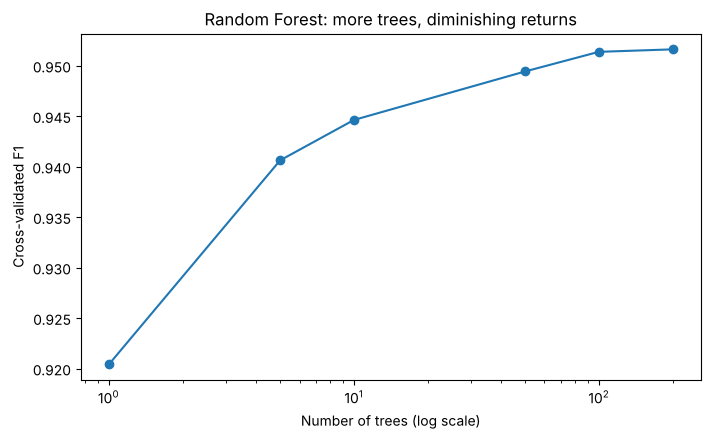

1      0.920
5      0.941
10     0.945
50     0.949
100    0.951
200    0.952
Name: CV F1, dtype: float64


In [19]:
tree_counts = [1, 5, 10, 50, 100, 200]
f1_by_size = [cross_validate(full_pipeline(RandomForestClassifier(n_estimators=n, random_state=RANDOM_STATE)),
                             X_train, y_train_clf, cv=clf_cv, scoring="f1")["test_score"].mean()
              for n in tree_counts]

plt.figure(figsize=(8, 4.5))
plt.plot(tree_counts, f1_by_size, marker="o")
plt.xscale("log")
plt.xlabel("Number of trees (log scale)")
plt.ylabel("Cross-validated F1")
plt.title("Random Forest: more trees, diminishing returns")
plt.show()
print(pd.Series(f1_by_size, index=tree_counts, name="CV F1").round(3))

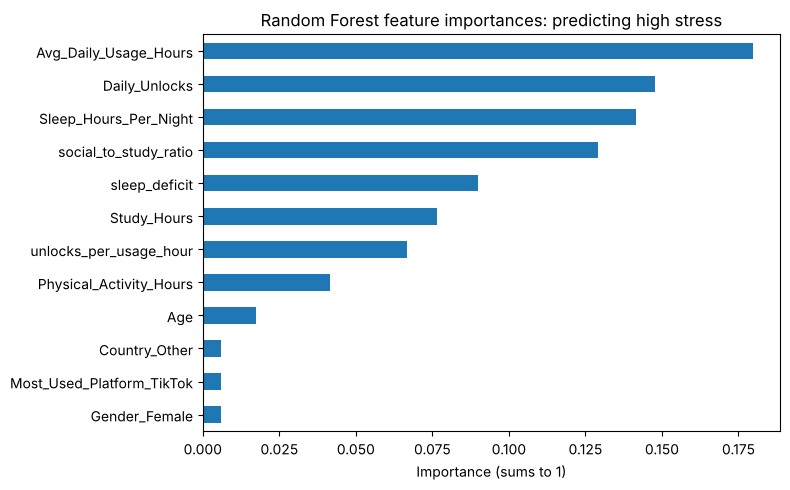

Avg_Daily_Usage_Hours        0.180
Daily_Unlocks                0.148
Sleep_Hours_Per_Night        0.141
social_to_study_ratio        0.129
sleep_deficit                0.090
Study_Hours                  0.077
unlocks_per_usage_hour       0.067
Physical_Activity_Hours      0.041
Age                          0.017
Country_Other                0.006
Most_Used_Platform_TikTok    0.006
Gender_Female                0.006
dtype: float64


In [20]:
forest = classifiers["Random Forest (200 trees)"].fit(X_train, y_train_clf)
importances = pd.Series(forest[-1].feature_importances_, index=feature_names(forest)).sort_values()
importances.tail(12).plot.barh(figsize=(8, 5))
plt.xlabel("Importance (sums to 1)")
plt.title("Random Forest feature importances: predicting high stress")
plt.tight_layout()
plt.show()
print(importances.sort_values(ascending=False).head(12).round(3))

In [21]:
log_reg = classifiers["Logistic Regression"].fit(X_train, y_train_clf)
log_coefs = pd.Series(log_reg[-1].coef_[0], index=feature_names(log_reg))
log_coefs = log_coefs.reindex(log_coefs.abs().sort_values(ascending=False).index)
print(pd.DataFrame({"Coefficient": log_coefs, "Odds ratio": np.exp(log_coefs)}).head(12).round(3))

                            Coefficient  Odds ratio
Country_Poland                    2.083       8.030
Sleep_Hours_Per_Night            -1.724       0.178
Country_China                     1.375       3.955
Most_Used_Platform_Twitter        1.318       3.737
social_to_study_ratio             1.176       3.242
Avg_Daily_Usage_Hours             1.142       3.133
Purpose_Of_Use_News              -1.134       0.322
Daily_Unlocks                     1.093       2.983
Country_Russia                    0.953       2.593
Country_Bangladesh               -0.932       0.394
Country_UK                       -0.805       0.447
Country_India                    -0.803       0.448


In [22]:
best_name = cv_results.index[0]
print("Best classifier by CV F1:", best_name)
cv_proba = cross_val_predict(classifiers[best_name], X_train, y_train_clf, cv=clf_cv, method="predict_proba")[:, 1]
threshold_rows = []
for t in [0.3, 0.4, 0.5, 0.6]:
    p = (cv_proba >= t).astype(int)
    threshold_rows.append({"Threshold": t, "Recall": recall_score(y_train_clf, p),
                           "Precision": precision_score(y_train_clf, p), "F1": f1_score(y_train_clf, p),
                           "Missed high-stress students": int(((p == 0) & (y_train_clf == 1)).sum())})
print(pd.DataFrame(threshold_rows).round(3))

Best classifier by CV F1: Random Forest (200 trees)


   Threshold  Recall  Precision     F1  Missed high-stress students
0        0.3   0.983      0.903  0.941                           42
1        0.4   0.971      0.930  0.950                           71
2        0.5   0.953      0.950  0.951                          115
3        0.6   0.924      0.969  0.946                          185


Regression (stress 1–4):
                     Test MAE  Test RMSE  Test R²
Usage only              0.396      0.490    0.774
Linear regression       0.361      0.448    0.811
Ridge (alpha=10.0)      0.361      0.448    0.811
Lasso (alpha=0.001)     0.362      0.448    0.811



Classification (high stress):
                           Accuracy  Precision  Recall     F1
Random Forest (200 trees)     0.950      0.959   0.959  0.959
Logistic Regression           0.908      0.922   0.928  0.925


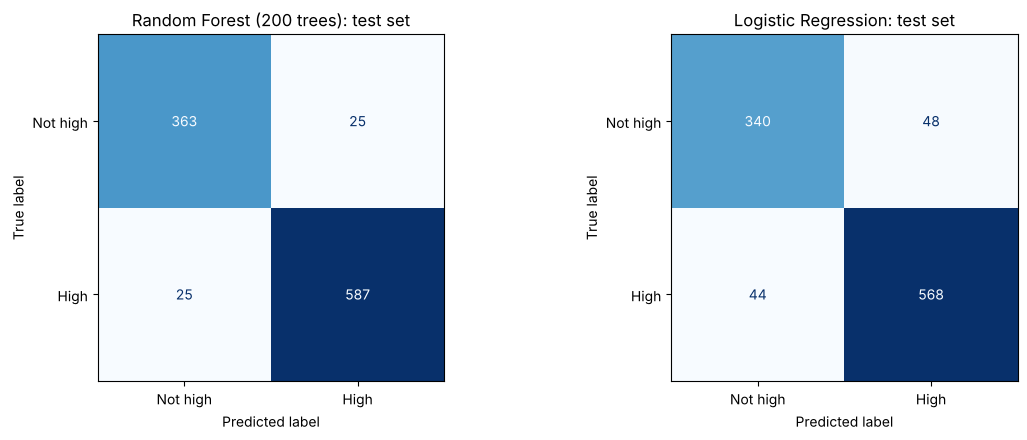

              precision    recall  f1-score   support

    Not high      0.936     0.936     0.936       388
        High      0.959     0.959     0.959       612

    accuracy                          0.950      1000
   macro avg      0.947     0.947     0.947      1000
weighted avg      0.950     0.950     0.950      1000



In [23]:
final_reg = {
    "Usage only": LinearRegression().fit(X_train[["Avg_Daily_Usage_Hours"]], y_train_reg),
    **{name: m.fit(X_train, y_train_reg) for name, m in reg_models.items()},
}
reg_test = {}
for name, m in final_reg.items():
    pred = m.predict(X_test[["Avg_Daily_Usage_Hours"]] if name == "Usage only" else X_test)
    reg_test[name] = {"Test MAE": mean_absolute_error(y_test_reg, pred),
                      "Test RMSE": np.sqrt(mean_squared_error(y_test_reg, pred)),
                      "Test R²": r2_score(y_test_reg, pred)}
print("Regression (stress 1–4):")
print(pd.DataFrame(reg_test).T.round(3))

final_clf = {name: classifiers[name].fit(X_train, y_train_clf) for name in [best_name, "Logistic Regression"]}
clf_test = {}
for name, m in final_clf.items():
    p = m.predict(X_test)
    clf_test[name] = {"Accuracy": accuracy_score(y_test_clf, p), "Precision": precision_score(y_test_clf, p),
                      "Recall": recall_score(y_test_clf, p), "F1": f1_score(y_test_clf, p)}
print("\nClassification (high stress):")
print(pd.DataFrame(clf_test).T.round(3))

fig, axes = plt.subplots(1, len(final_clf), figsize=(6 * len(final_clf), 4.5))
for ax, (name, m) in zip(np.atleast_1d(axes), final_clf.items()):
    ConfusionMatrixDisplay.from_predictions(y_test_clf, m.predict(X_test), display_labels=["Not high", "High"],
                                            cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(f"{name}: test set")
plt.tight_layout()
plt.show()

print(classification_report(y_test_clf, final_clf[best_name].predict(X_test),
                            target_names=["Not high", "High"], digits=3))